# 01 - Data Exploration (EDA)
**Project:** Rossmann Store Sales Forecasting

The goal here is to get familiar with the data before doing anything to it — shape, types, missing values,
distributions, and how the features relate to `Sales`.
No cleaning or transformations here — that's all handled in the notebooks that follow.

**What's covered:**
1. Load the data & take a first look
2. Column reference / data dictionary
3. Data types + quick date breakdown
4. Where are the NaNs?
5. Duplicate rows & basic sanity checks
6. Descriptive stats
7. Univariate distributions
8. Features vs `Sales`
9. Sales over time
10. Correlation matrix
11. Store-by-store view
12. Key takeaways

## 1. Load the data

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [ ]:
DATA_PATH = "../data/train.csv"   # change this if the file is in another folder

# StateHoliday mixes numbers and letters (0 / a / b / c) -> read it as text
df = pd.read_csv(DATA_PATH, dtype={"StateHoliday": "str"})
df["Date"] = pd.to_datetime(df["Date"])

print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
display(df.head())

Rows: 1,017,209  |  Columns: 18


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,"1,270.00",9.00,"2,008.00",0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9.00,"2,009.00",0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,"29,910.00",4.00,"2,015.00",0,NaN,NaN,NaN


In [ ]:
display(df.tail())
df.info()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,"1,900.00",6.00,"2,014.00",1,31.00,"2,013.00","Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,"1,880.00",4.00,"2,006.00",0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,"9,260.00",NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.00,NaN,NaN,0,NaN,NaN,NaN
1017208,1115,2,2013-01-01,0,0,0,0,a,1,d,c,"5,350.00",NaN,NaN,1,22.00,"2,012.00","Mar,Jun,Sept,Dec"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[ns]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  object        
 10  Assortment                 1017209 non-null  object        
 11  CompetitionDistance        1014567 no

In [ ]:
print("Date range      :", df["Date"].min().date(), "->", df["Date"].max().date())
print("Days in range   :", (df["Date"].max() - df["Date"].min()).days + 1)
print("Number of stores:", df["Store"].nunique())
print(f"Memory usage    : {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB")

Date range      : 2013-01-01 -> 2015-07-31
Days in range   : 942
Number of stores: 1115
Memory usage    : 315.5 MB


## 2. Data dictionary

| Column | Meaning | Kind |
|---|---|---|
| `Store` | Store id (1-1115) | identifier |
| `DayOfWeek` | 1 = Monday ... 7 = Sunday | ordinal / categorical |
| `Date` | Calendar date | datetime |
| `Sales` | Turnover of the day - **the target** | numeric (target) |
| `Customers` | Number of customers that day | numeric |
| `Open` | 0 = closed, 1 = open | binary |
| `Promo` | Is the store running a promotion that day | binary |
| `StateHoliday` | `a` public, `b` Easter, `c` Christmas, `0` none | categorical |
| `SchoolHoliday` | School holiday affects the store that day | binary |
| `StoreType` | 4 store models: a, b, c, d | categorical (store level) |
| `Assortment` | a = basic, b = extra, c = extended | categorical (store level) |
| `CompetitionDistance` | Distance (m) to the nearest competitor | numeric (store level) |
| `CompetitionOpenSinceMonth/Year` | When the nearest competitor opened | numeric (store level) |
| `Promo2` | Store takes part in a continuing promotion | binary (store level) |
| `Promo2SinceWeek/Year` | When the store joined Promo2 | numeric (store level) |
| `PromoInterval` | Months in which Promo2 restarts | categorical (store level) |

> "Store level" = the value never changes for a given store; it is repeated on every row of that store.

## 3. Data types & simple date features
We add a few date parts **only for exploration** (the real feature engineering is in notebook 02).

In [ ]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

display(df.dtypes.to_frame("dtype").T)
display(df[["Date", "Year", "Month", "Day", "WeekOfYear", "DayOfWeek"]].head())

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear
dtype,int64,int64,datetime64[ns],int64,int64,int64,int64,object,int64,object,object,float64,float64,float64,int64,float64,float64,object,int32,int32,int32,int64


,Date,Year,Month,Day,WeekOfYear,DayOfWeek
0,2015-07-31,2015,7,31,31,5
1,2015-07-31,2015,7,31,31,5
2,2015-07-31,2015,7,31,31,5
3,2015-07-31,2015,7,31,31,5
4,2015-07-31,2015,7,31,31,5


## 4. Missing values

,missing_count,missing_pct
Promo2SinceYear,508031,49.94
Promo2SinceWeek,508031,49.94
PromoInterval,508031,49.94
CompetitionOpenSinceMonth,323348,31.79
CompetitionOpenSinceYear,323348,31.79
CompetitionDistance,2642,0.26


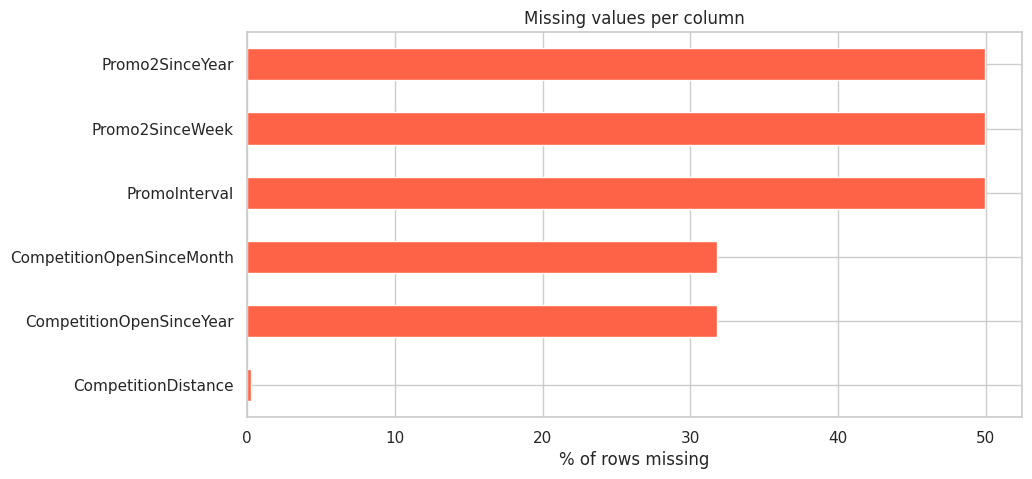

In [ ]:
missing = (
    df.isna().sum().to_frame("missing_count")
      .assign(missing_pct=lambda t: t["missing_count"] / len(df) * 100)
      .query("missing_count > 0")
      .sort_values("missing_count", ascending=False)
)
display(missing)

ax = missing["missing_pct"].plot.barh(color="tomato")
ax.invert_yaxis()
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per column")
plt.show()

**Why are they missing?** Let's check whether the gaps are *structural* (they mean "not applicable") or real data loss.

In [ ]:
promo2_cols = ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]

print("Rows with Promo2 == 0 where ALL Promo2 columns are NaN :",
      f"{df.loc[df['Promo2'] == 0, promo2_cols].isna().all(axis=1).mean():.1%}")
print("Rows with Promo2 == 1 that still miss Promo2 info       :",
      df.loc[df["Promo2"] == 1, promo2_cols].isna().any(axis=1).sum())
print()
print("Stores with missing CompetitionDistance      :", df.loc[df["CompetitionDistance"].isna(), "Store"].nunique())
print("Stores with missing CompetitionOpenSince info:", df.loc[df["CompetitionOpenSinceYear"].isna(), "Store"].nunique())

Rows with Promo2 == 0 where ALL Promo2 columns are NaN : 100.0%
Rows with Promo2 == 1 that still miss Promo2 info       : 0

Stores with missing CompetitionDistance      : 3
Stores with missing CompetitionOpenSince info: 354


**Reading:** the `Promo2*` / `PromoInterval` gaps are *structural* (stores that don't take part in Promo2 have nothing to report).
`CompetitionDistance` has only a few missing stores, while `CompetitionOpenSince*` is missing for many stores.
How to fill them is decided in **notebook 03 - Missing Values Handling**.

## 5. Duplicates & sanity checks

In [ ]:
print("Fully duplicated rows        :", df.duplicated().sum())
print("Duplicated (Store, Date) keys:", df.duplicated(["Store", "Date"]).sum())

checks = {
    "Closed days (Open = 0) with Sales > 0": ((df["Open"] == 0) & (df["Sales"] > 0)).sum(),
    "Open days (Open = 1) with Sales == 0":  ((df["Open"] == 1) & (df["Sales"] == 0)).sum(),
    "Open days with Customers == 0":         ((df["Open"] == 1) & (df["Customers"] == 0)).sum(),
    "Negative Sales":                        (df["Sales"] < 0).sum(),
    "Negative Customers":                    (df["Customers"] < 0).sum(),
}
display(pd.Series(checks, name="rows").to_frame())

Fully duplicated rows        : 0
Duplicated (Store, Date) keys: 0


,rows
Closed days (Open = 0) with Sales > 0,0
Open days (Open = 1) with Sales == 0,54
Open days with Customers == 0,52
Negative Sales,0
Negative Customers,0


In [ ]:
# Does every store have a row for every day?
expected_days = (df["Date"].max() - df["Date"].min()).days + 1
rows_per_store = df.groupby("Store").size()
print("Days in the period:", expected_days)
display(rows_per_store.value_counts().rename_axis("rows per store").to_frame("number of stores"))

Days in the period: 942


,number of stores
rows per store,
942,934
758,180
941,1


## 6. Descriptive statistics
Closed days always have `Sales = 0`, so they would pull every average down. From here on we also keep an **`open_df`**
(only days where the store was open) for the sales-related plots.

In [ ]:
num_cols = ["Sales", "Customers", "CompetitionDistance", "CompetitionOpenSinceMonth",
            "CompetitionOpenSinceYear", "Promo2SinceWeek", "Promo2SinceYear"]
display(df[num_cols].describe().T)

open_df = df[df["Open"] == 1].copy()
print(f"\nOpen days: {len(open_df):,} of {len(df):,} rows ({len(open_df) / len(df):.1%})")

,count,mean,std,min,25%,50%,75%,max
Sales,"1,017,209.00","5,773.82","3,849.93",0.00,"3,727.00","5,744.00","7,856.00","41,551.00"
Customers,"1,017,209.00",633.15,464.41,0.00,405.00,609.00,837.00,"7,388.00"
CompetitionDistance,"1,014,567.00","5,430.09","7,715.32",20.00,710.00,"2,330.00","6,890.00","75,860.00"
CompetitionOpenSinceMonth,"693,861.00",7.22,3.21,1.00,4.00,8.00,10.00,12.00
CompetitionOpenSinceYear,"693,861.00","2,008.69",5.99,"1,900.00","2,006.00","2,010.00","2,013.00","2,015.00"
Promo2SinceWeek,"509,178.00",23.27,14.10,1.00,13.00,22.00,37.00,50.00
Promo2SinceYear,"509,178.00","2,011.75",1.66,"2,009.00","2,011.00","2,012.00","2,013.00","2,015.00"



Open days: 844,392 of 1,017,209 rows (83.0%)


In [ ]:
for col in ["StateHoliday", "StoreType", "Assortment", "PromoInterval"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False, normalize=True).mul(100).round(2).astype(str) + " %")
    print()

--- StateHoliday ---
StateHoliday
0    96.95 %
a     1.99 %
b     0.66 %
c      0.4 %
Name: proportion, dtype: object

--- StoreType ---
StoreType
a    54.23 %
d    30.76 %
c    13.45 %
b     1.56 %
Name: proportion, dtype: object

--- Assortment ---
Assortment
a    52.84 %
c    46.35 %
b     0.82 %
Name: proportion, dtype: object

--- PromoInterval ---
PromoInterval
NaN                 49.94 %
Jan,Apr,Jul,Oct     28.82 %
Feb,May,Aug,Nov     11.66 %
Mar,Jun,Sept,Dec     9.58 %
Name: proportion, dtype: object



## 7. Univariate analysis
### 7.1 Numeric features

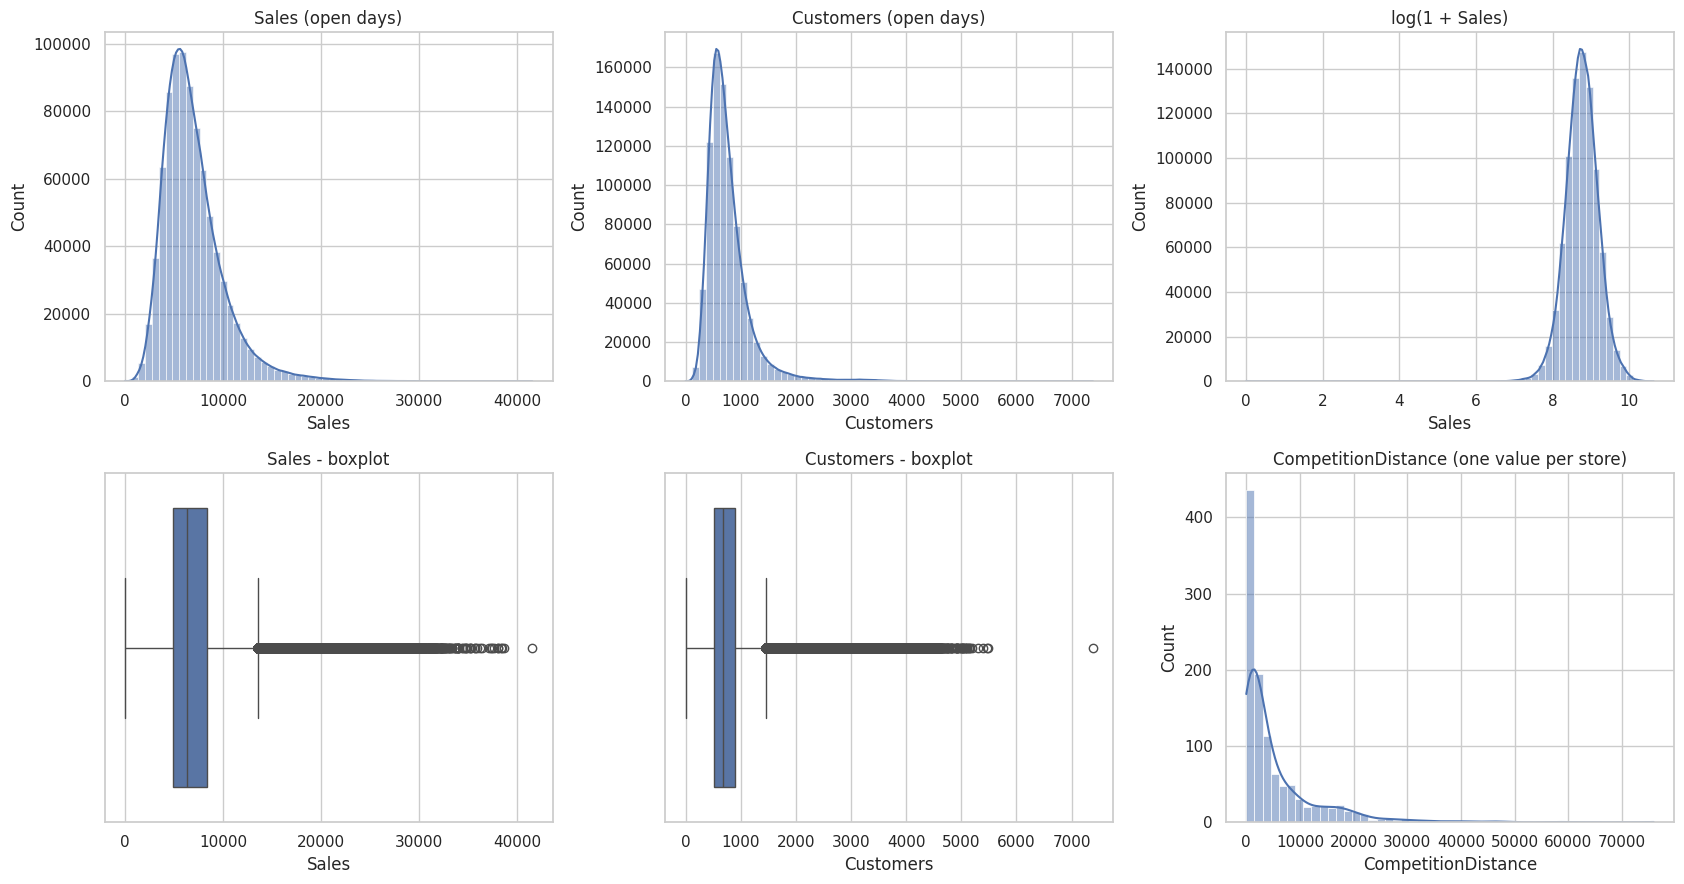

In [ ]:
stores = df.drop_duplicates("Store").set_index("Store")   # one row per store (for store-level features)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(open_df["Sales"], bins=60, kde=True, ax=axes[0, 0]);          axes[0, 0].set_title("Sales (open days)")
sns.histplot(open_df["Customers"], bins=60, kde=True, ax=axes[0, 1]);      axes[0, 1].set_title("Customers (open days)")
sns.histplot(np.log1p(open_df["Sales"]), bins=60, kde=True, ax=axes[0, 2]); axes[0, 2].set_title("log(1 + Sales)")
sns.boxplot(x=open_df["Sales"], ax=axes[1, 0]);                            axes[1, 0].set_title("Sales - boxplot")
sns.boxplot(x=open_df["Customers"], ax=axes[1, 1]);                        axes[1, 1].set_title("Customers - boxplot")
sns.histplot(stores["CompetitionDistance"].dropna(), bins=50, kde=True, ax=axes[1, 2])
axes[1, 2].set_title("CompetitionDistance (one value per store)")
plt.tight_layout()
plt.show()

In [ ]:
shape = pd.DataFrame({
    "skewness": [open_df["Sales"].skew(), open_df["Customers"].skew(), stores["CompetitionDistance"].skew()],
    "kurtosis": [open_df["Sales"].kurt(), open_df["Customers"].kurt(), stores["CompetitionDistance"].kurt()],
}, index=["Sales", "Customers", "CompetitionDistance"])
display(shape)

,skewness,kurtosis
Sales,1.59,4.85
Customers,2.79,13.31
CompetitionDistance,2.93,13.10


**Reading:** all three are **right-skewed** (long tail of big values), `CompetitionDistance` the most. This matters for
outlier handling (notebook 04), transformations (notebook 06) and scaling (notebook 05).

### 7.2 Categorical & binary features

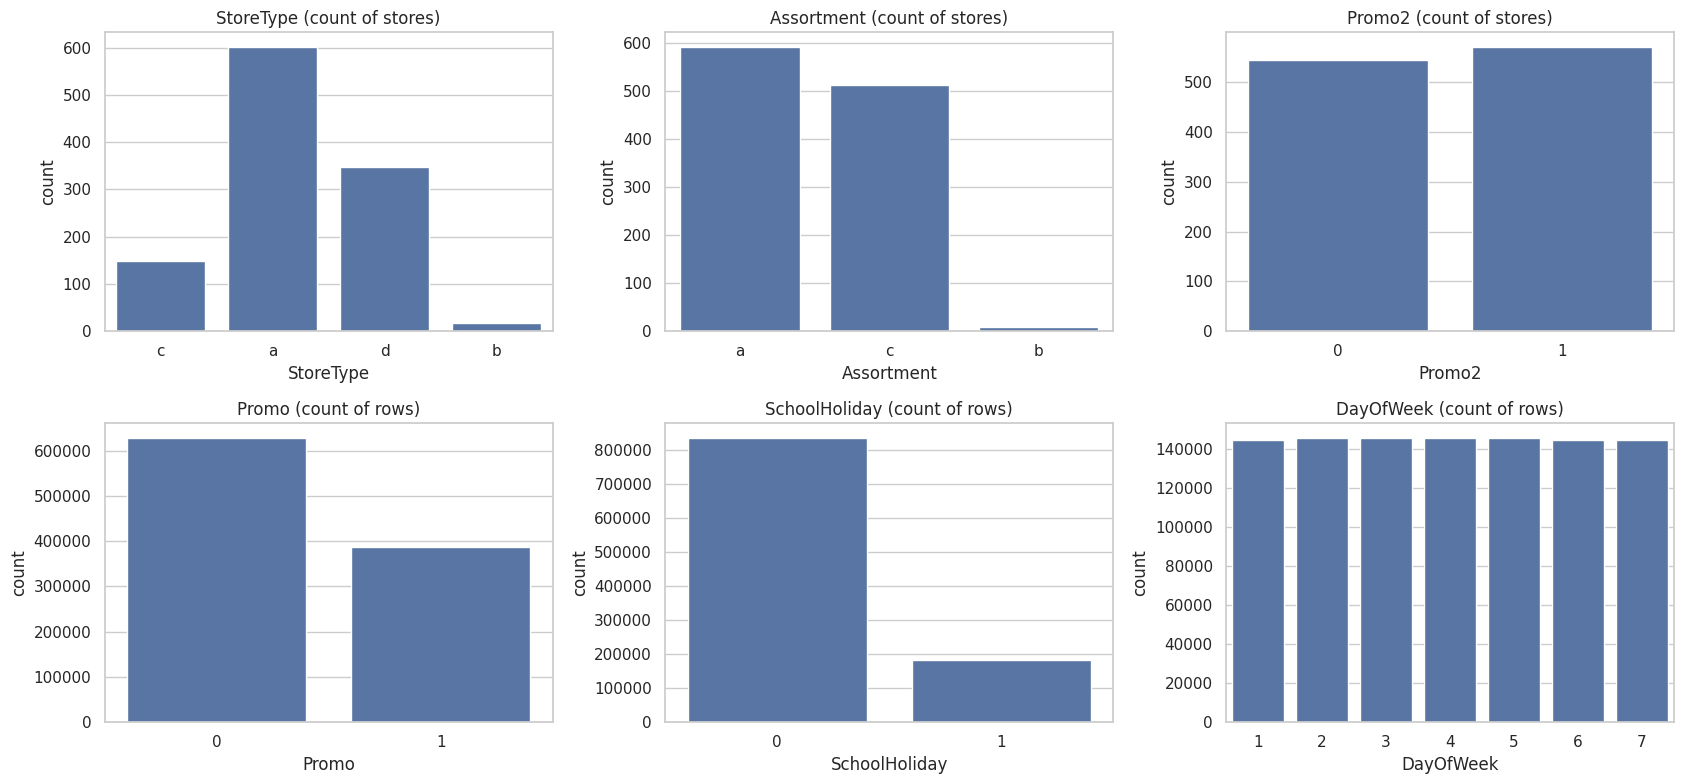

StateHoliday (rows):
StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
plots = [(stores, "StoreType"), (stores, "Assortment"), (stores, "Promo2"),
         (df, "Promo"), (df, "SchoolHoliday"), (df, "DayOfWeek")]
for ax, (data, col) in zip(axes.ravel(), plots):
    sns.countplot(data=data, x=col, ax=ax)
    scope = "stores" if data is stores else "rows"
    ax.set_title(f"{col} (count of {scope})")
plt.tight_layout()
plt.show()

print("StateHoliday (rows):")
print(df["StateHoliday"].value_counts())

## 8. Bivariate analysis - features vs `Sales`
### 8.1 Average sales by category (open days only)

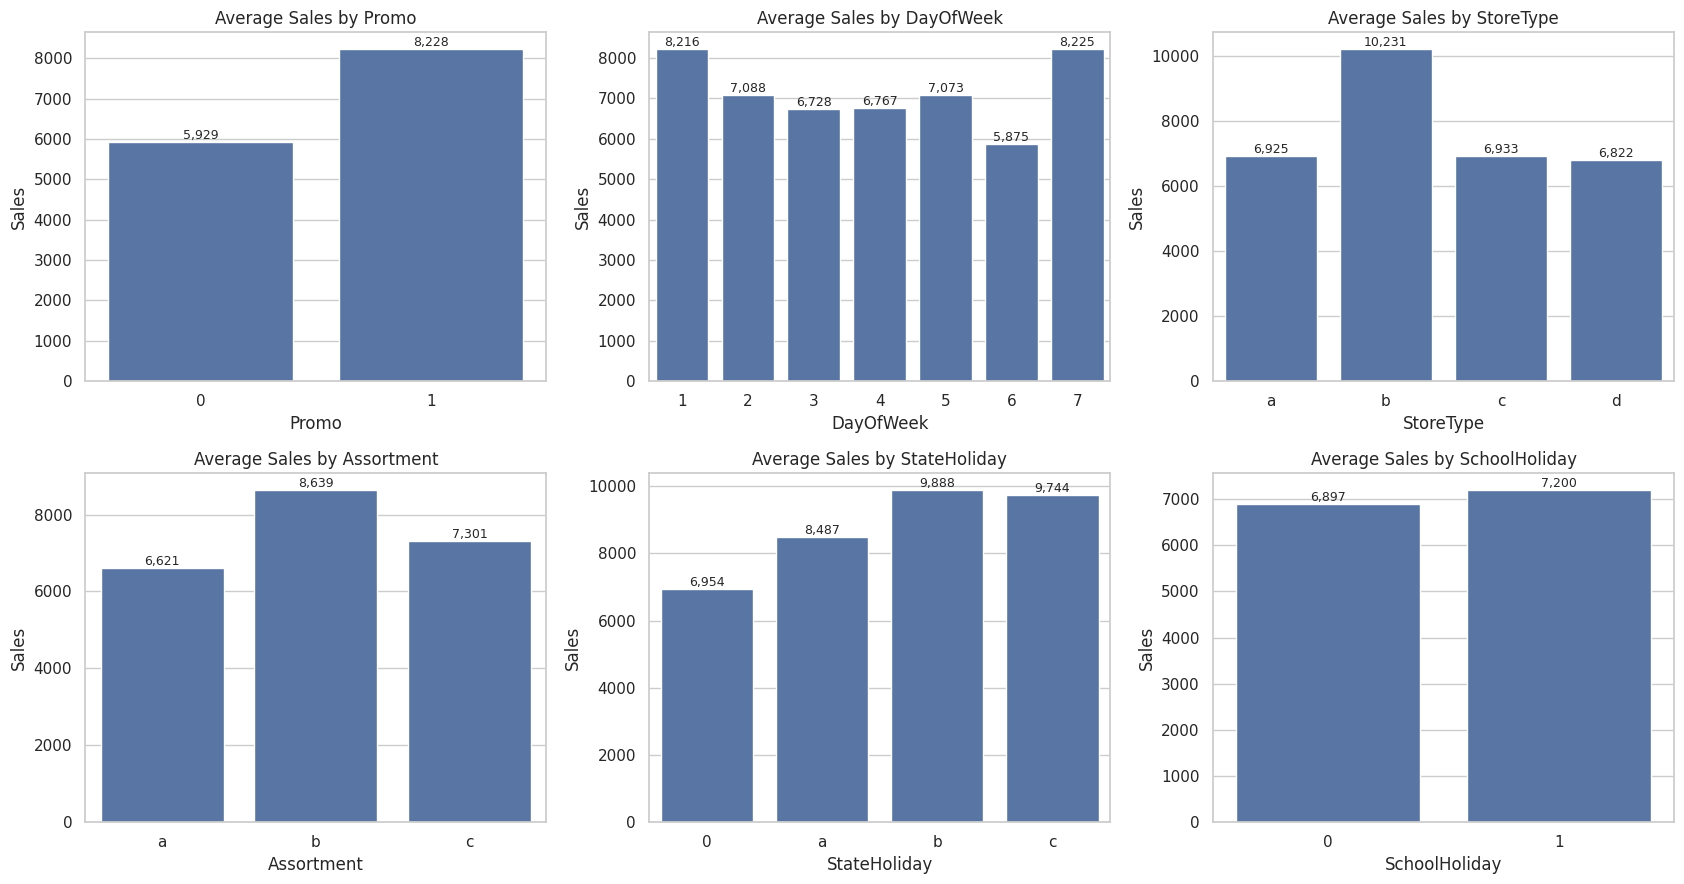

Promo effect: 5,929 -> 8,228  (+38.8%)


In [ ]:
def mean_sales_by(col, ax, data=open_df):
    g = data.groupby(col)["Sales"].mean().reset_index()
    sns.barplot(data=g, x=col, y="Sales", ax=ax)
    ax.set_title(f"Average Sales by {col}")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), ["Promo", "DayOfWeek", "StoreType", "Assortment", "StateHoliday", "SchoolHoliday"]):
    mean_sales_by(col, ax)
plt.tight_layout()
plt.show()

promo = open_df.groupby("Promo")["Sales"].mean()
print(f"Promo effect: {promo[0]:,.0f} -> {promo[1]:,.0f}  ({promo[1] / promo[0] - 1:+.1%})")

In [ ]:
# Why are Sundays "strong"? Because only a few stores open on Sunday.
open_share = df.groupby("DayOfWeek")["Open"].mean().mul(100).round(1)
print("% of store-days that are OPEN, by day of week:")
display(open_share.to_frame("open_%").T)

display(open_df.pivot_table(index="DayOfWeek", columns="Promo", values="Sales", aggfunc="mean").round(0))

% of store-days that are OPEN, by day of week:


DayOfWeek,1,2,3,4,5,6,7
open_%,95.00,98.80,97.40,92.30,95.10,99.50,2.50


Promo,0,1
DayOfWeek,,
1,"6,223.00","9,773.00"
2,"5,716.00","8,277.00"
3,"5,617.00","7,685.00"
4,"5,750.00","7,598.00"
5,"6,344.00","7,744.00"
6,"5,875.00",NaN
7,"8,225.00",NaN


### 8.2 Sales vs Customers and sales per customer

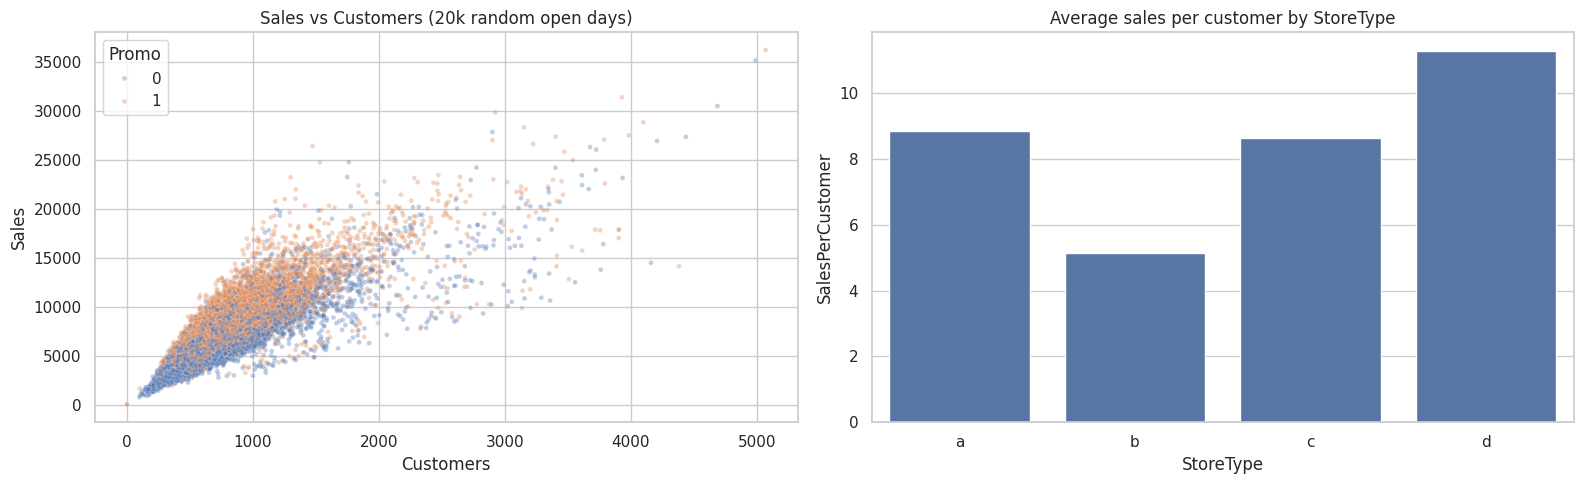

Correlation Sales ~ Customers: 0.824


In [ ]:
sample = open_df.sample(20_000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=sample, x="Customers", y="Sales", hue="Promo", alpha=0.35, s=12, ax=axes[0])
axes[0].set_title("Sales vs Customers (20k random open days)")

spc = open_df[open_df["Customers"] > 0].assign(SalesPerCustomer=lambda t: t["Sales"] / t["Customers"])
sns.barplot(data=spc.groupby("StoreType")["SalesPerCustomer"].mean().reset_index(),
            x="StoreType", y="SalesPerCustomer", ax=axes[1])
axes[1].set_title("Average sales per customer by StoreType")
plt.tight_layout()
plt.show()

print("Correlation Sales ~ Customers:", round(open_df["Sales"].corr(open_df["Customers"]), 3))

### 8.3 Competition and store attributes (store level)

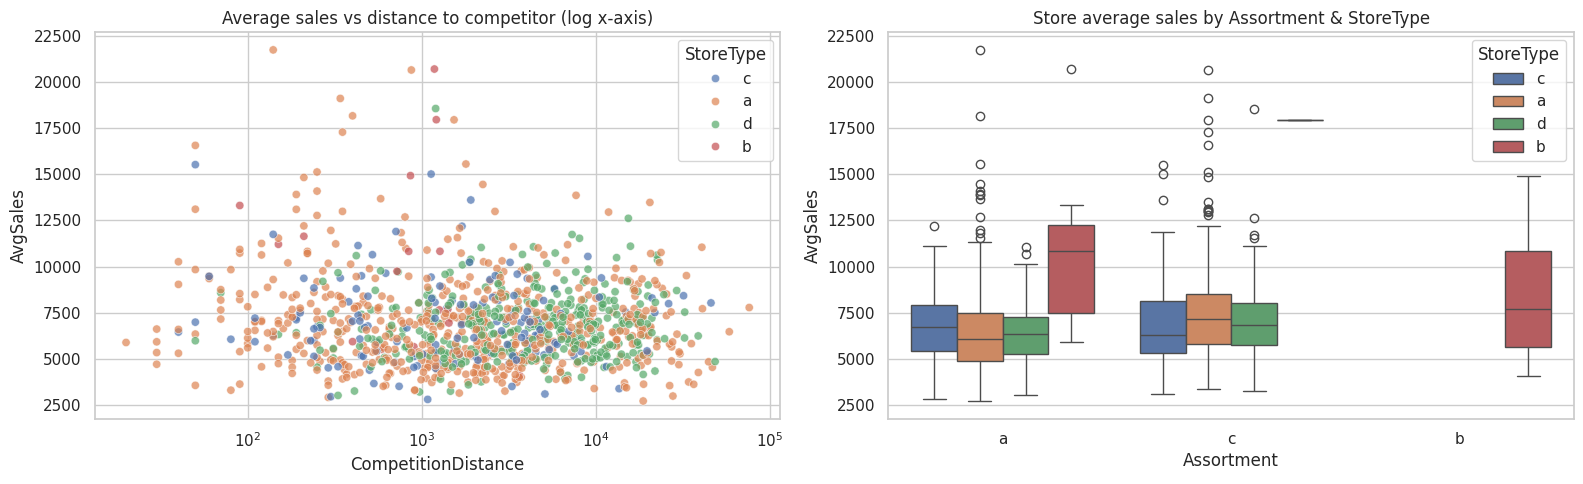

Spearman (CompetitionDistance ~ AvgSales): -0.028


In [ ]:
store_view = (open_df.groupby("Store")["Sales"].mean().rename("AvgSales").to_frame()
              .join(stores[["StoreType", "Assortment", "CompetitionDistance"]]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=store_view, x="CompetitionDistance", y="AvgSales", hue="StoreType", alpha=0.7, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_title("Average sales vs distance to competitor (log x-axis)")
sns.boxplot(data=store_view, x="Assortment", y="AvgSales", hue="StoreType", ax=axes[1])
axes[1].set_title("Store average sales by Assortment & StoreType")
plt.tight_layout()
plt.show()

print("Spearman (CompetitionDistance ~ AvgSales):",
      round(store_view["CompetitionDistance"].corr(store_view["AvgSales"], method="spearman"), 3))

## 9. Sales over time

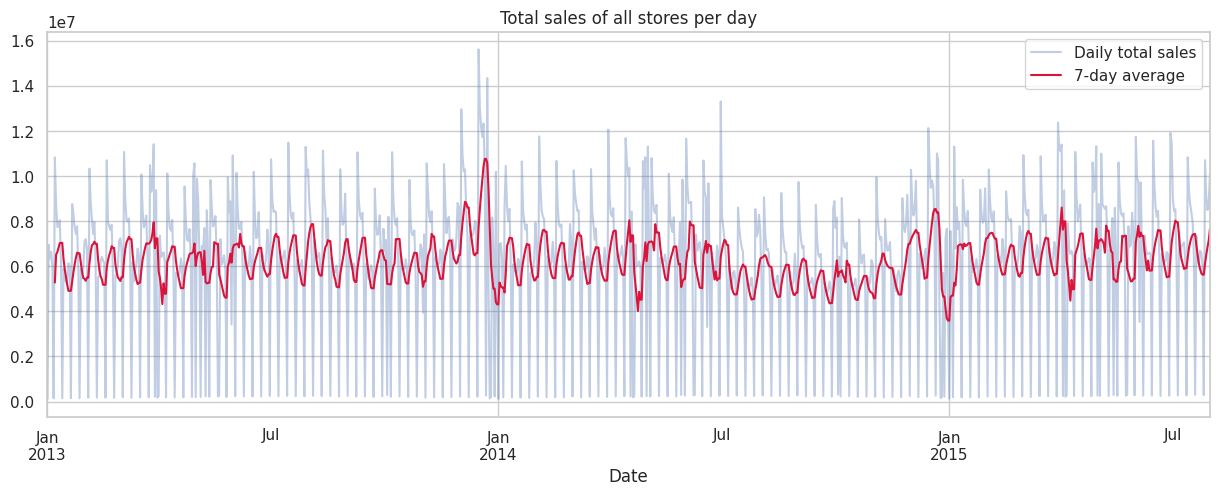

In [ ]:
daily = df.groupby("Date")["Sales"].sum()
fig, ax = plt.subplots(figsize=(15, 5))
daily.plot(ax=ax, alpha=0.35, label="Daily total sales")
daily.rolling(7).mean().plot(ax=ax, color="crimson", label="7-day average")
ax.set_title("Total sales of all stores per day")
ax.legend()
plt.show()

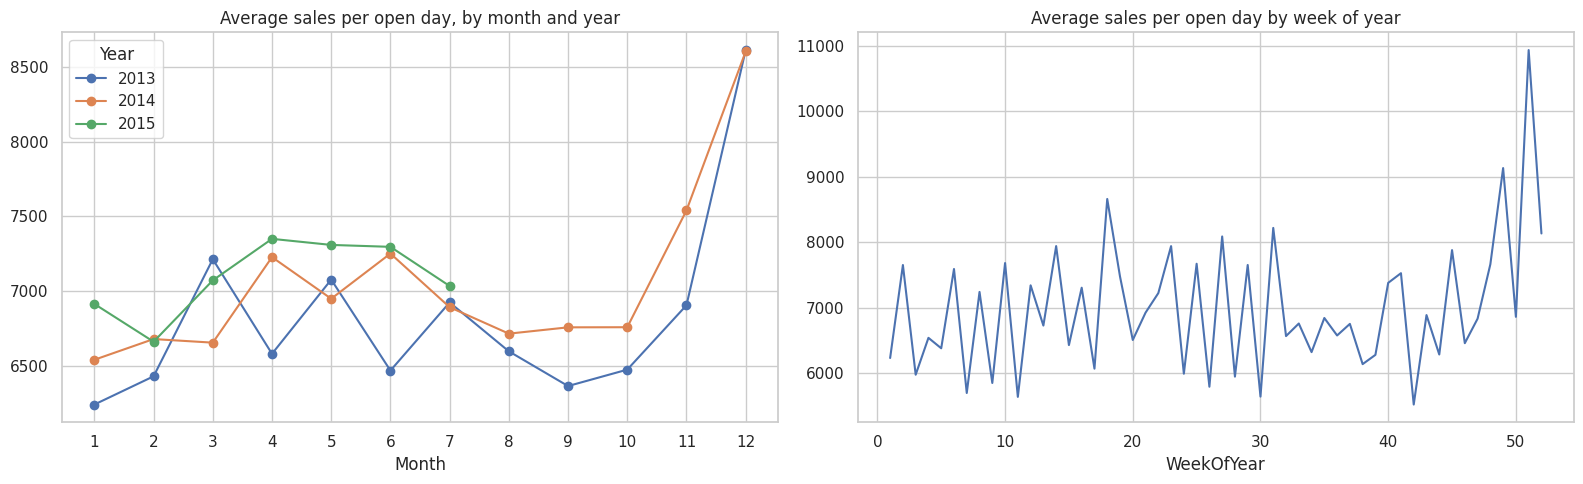

,open_days,avg_sales
Year,,
2013,337943,"6,814.39"
2014,310417,"7,025.40"
2015,196032,"7,088.13"


Note: 2015 only covers January-July.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

pivot = open_df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="mean")
pivot.plot(marker="o", ax=axes[0])
axes[0].set_title("Average sales per open day, by month and year")
axes[0].set_xticks(range(1, 13))

week = open_df.groupby("WeekOfYear")["Sales"].mean()
week.plot(ax=axes[1])
axes[1].set_title("Average sales per open day by week of year")
plt.tight_layout()
plt.show()

display(open_df.groupby("Year")["Sales"].agg(["count", "mean"]).rename(columns={"count": "open_days", "mean": "avg_sales"}))
print("Note: 2015 only covers January-July.")

## 10. Correlation

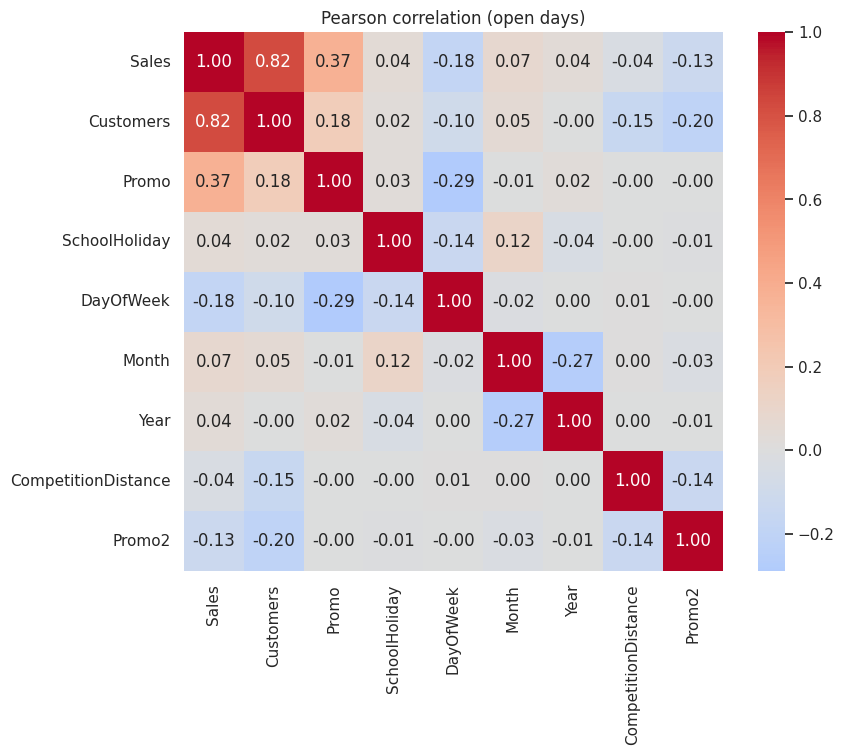

,corr with Sales
Customers,0.82
Promo,0.37
DayOfWeek,-0.18
Promo2,-0.13
Month,0.07
SchoolHoliday,0.04
CompetitionDistance,-0.04
Year,0.04


In [ ]:
corr_cols = ["Sales", "Customers", "Promo", "SchoolHoliday", "DayOfWeek", "Month", "Year",
             "CompetitionDistance", "Promo2"]
corr = open_df[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Pearson correlation (open days)")
plt.show()

display(corr["Sales"].drop("Sales").sort_values(key=abs, ascending=False).to_frame("corr with Sales"))

## 11. Store-level breakdown

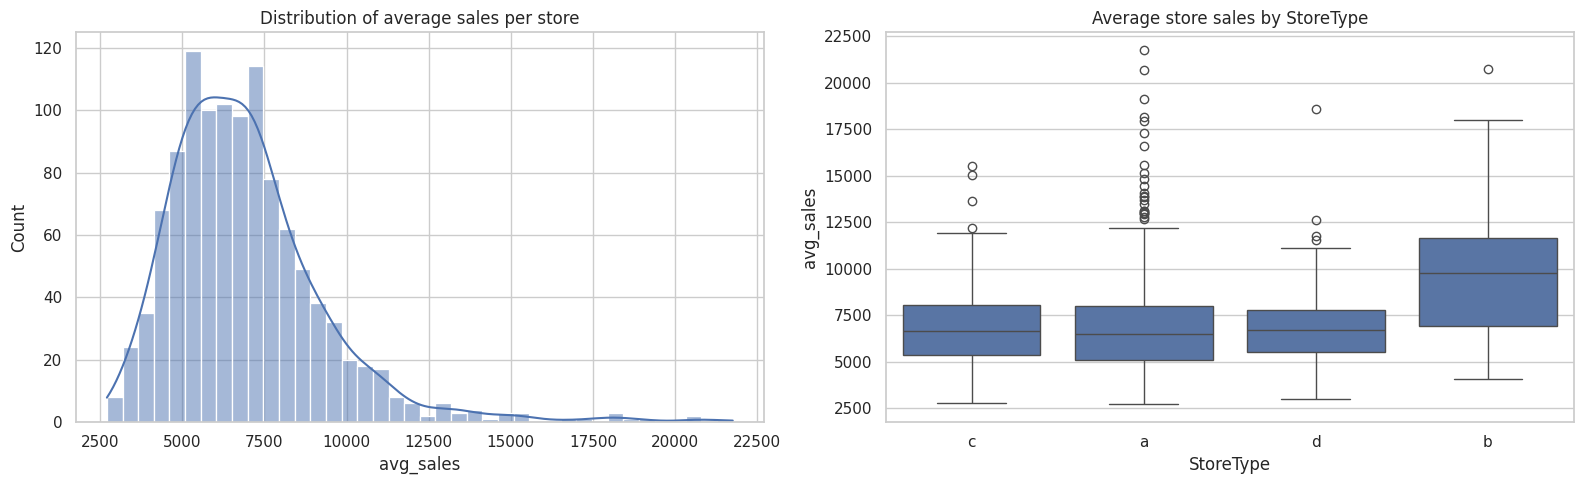

Top 5 stores by average sales:


,avg_sales,std_sales,open_days
Store,,,
817,"21,757.48","4,674.80",784
262,"20,718.52","4,668.88",942
1114,"20,666.56","3,452.94",784
251,"19,123.07","3,547.64",779
842,"18,574.80","3,788.99",622


Bottom 5 stores by average sales:


,avg_sales,std_sales,open_days
Store,,,
307,"2,703.74","1,032.83",782
543,"2,790.38","1,237.70",781
198,"2,900.60","1,597.76",782
208,"2,936.29",716.53,784
841,"2,972.61","1,096.26",780


In [ ]:
store_sales = open_df.groupby("Store")["Sales"].agg(["mean", "std", "count"]).rename(columns={"mean": "avg_sales", "std": "std_sales", "count": "open_days"})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(store_sales["avg_sales"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of average sales per store")
sns.boxplot(data=store_sales.join(stores["StoreType"]), x="StoreType", y="avg_sales", ax=axes[1])
axes[1].set_title("Average store sales by StoreType")
plt.tight_layout()
plt.show()

print("Top 5 stores by average sales:")
display(store_sales.sort_values("avg_sales", ascending=False).head(5))
print("Bottom 5 stores by average sales:")
display(store_sales.sort_values("avg_sales").head(5))

## 12. Key findings & hand-off
**Dataset:** 1,017,209 rows x 18 columns, 1,115 stores, 2013-01-01 -> 2015-07-31 (942 days). One row = one store on one day.
No duplicated rows and no duplicated (Store, Date) pairs.

**Data quality**
- **Missing values:** `Promo2SinceWeek`, `Promo2SinceYear`, `PromoInterval` (49.9%) are *structural* - they are empty exactly when `Promo2 = 0`.
  `CompetitionOpenSinceMonth/Year` (31.8%, 354 stores) and `CompetitionDistance` (0.26%, 3 stores) are genuine gaps.
- **Closed days:** 17% of rows have `Open = 0` and always `Sales = 0` -> they must be excluded (or handled) when analysing / modelling sales.
- **Suspicious rows:** 54 open days with `Sales = 0` and 52 open days with `Customers = 0`.
- **Incomplete history:** 180 stores have only 758 days instead of 942 (a gap in their history), 1 store has 941.
- `CompetitionOpenSinceYear` has a minimum of 1900, which is not a realistic opening year (outlier / data error).
- `StateHoliday` mixes `0` and `"0"` in the raw file, so it has to be read as text.

**Distributions:** `Sales` (skew 1.6), `Customers` (skew 2.8) and `CompetitionDistance` (skew 2.9) are right-skewed with long tails.

**What drives sales**
- `Customers` is by far the strongest relationship (r = 0.82) - but it is **not known in advance** when forecasting, so it must be used carefully.
- **Promotions:** average sales per open day 5,929 -> 8,228 (**+38.8%**) when `Promo = 1`; correlation with `Sales` is 0.37. Promos never run on Saturday / Sunday.
- **Day of week:** Monday is the strongest weekday. Sunday looks strong (8,225) only because just **2.5%** of store-days are open on Sunday (the few open stores are big ones).
- **Store type:** type `b` stores sell far more than a / c / d; `Assortment` and `Promo2` also show differences.
- **Competition distance** shows almost no monotonic relation with average sales (Spearman -0.03).
- **Seasonality:** clear weekly pattern and a year-end (December) peak; sales level is slightly rising from 2013 to 2015.

**Hand-off to the next notebooks**
| Notebook | What this EDA tells it |
|---|---|
| 02 Cleaning & Feature Engineering | Drop/flag closed days, check the 54 + 52 odd rows, build date features, fix `StateHoliday` type |
| 03 Missing Values | Treat structural `Promo2*` gaps differently from the real `Competition*` gaps |
| 04 Outliers | `Sales`, `Customers`, `CompetitionDistance` have long tails; `CompetitionOpenSinceYear = 1900` |
| 05 Numerical Scaling | Features have very different ranges (months 1-12, years ~2000, distance up to 75,860) |
| 06 Numerical Transformations | Skewed features are candidates for log / power transforms |
| 07 Categorical Handling | `StoreType`, `Assortment`, `StateHoliday`, `PromoInterval`, `DayOfWeek` |
| 08 Full Pipeline | Combine all of the above in one reproducible pipeline |